# Atelier 1: Regression
Asmaa Atouailaa — FST Tanger

The goal is to predict a stock's closing price on the next trading day using today's open, close, low, high and volume. These inputs are available after today's market closes.

Dataset: [NYSE](https://www.kaggle.com/datasets/dgawlik/nyse). Run the cells in order in Colab and upload `prices-split-adjusted.csv` when asked.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving prices-split-adjusted.csv to prices-split-adjusted (1).csv


In [4]:
import pandas as pd
import io

csv_name = next(name for name in uploaded if name.lower().endswith(".csv"))
df = pd.read_csv(io.BytesIO(uploaded[csv_name]))
df.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


## 1. Exploring the data
First, check the size of the table, column types, missing values and duplicates.

In [5]:
print("Rows and columns:", df.shape)

df.info()

print("\nMissing values per column:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB

Missing values per column:
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Duplicate rows: 0


In [6]:
df["date"] = pd.to_datetime(df["date"])

print("Number of companies:", df["symbol"].nunique())
print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Duplicate rows:", df.duplicated().sum())

display(df.describe())

Number of companies: 501
First date: 2010-01-04 00:00:00
Last date: 2016-12-30 00:00:00
Duplicate rows: 0


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


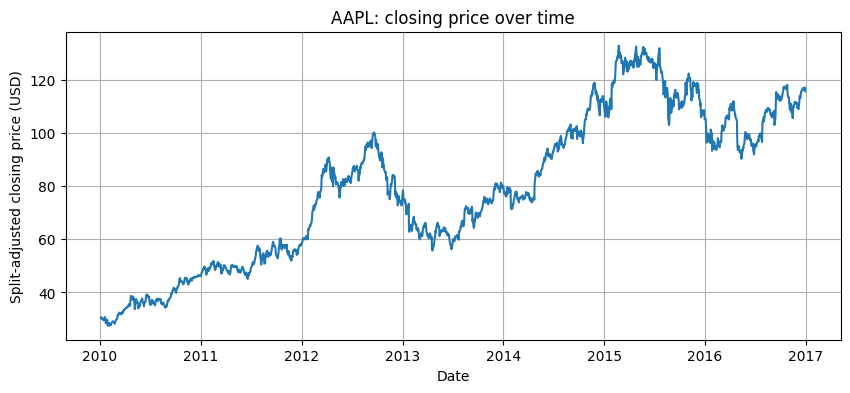

In [9]:
import matplotlib.pyplot as plt

stock = df[df["symbol"] == "AAPL"].sort_values("date")

plt.figure(figsize=(10, 4))
plt.plot(stock["date"], stock["close"])
plt.title("AAPL: closing price over time")
plt.xlabel("Date")
plt.ylabel("Split-adjusted closing price (USD)")
plt.grid(True)
plt.show()

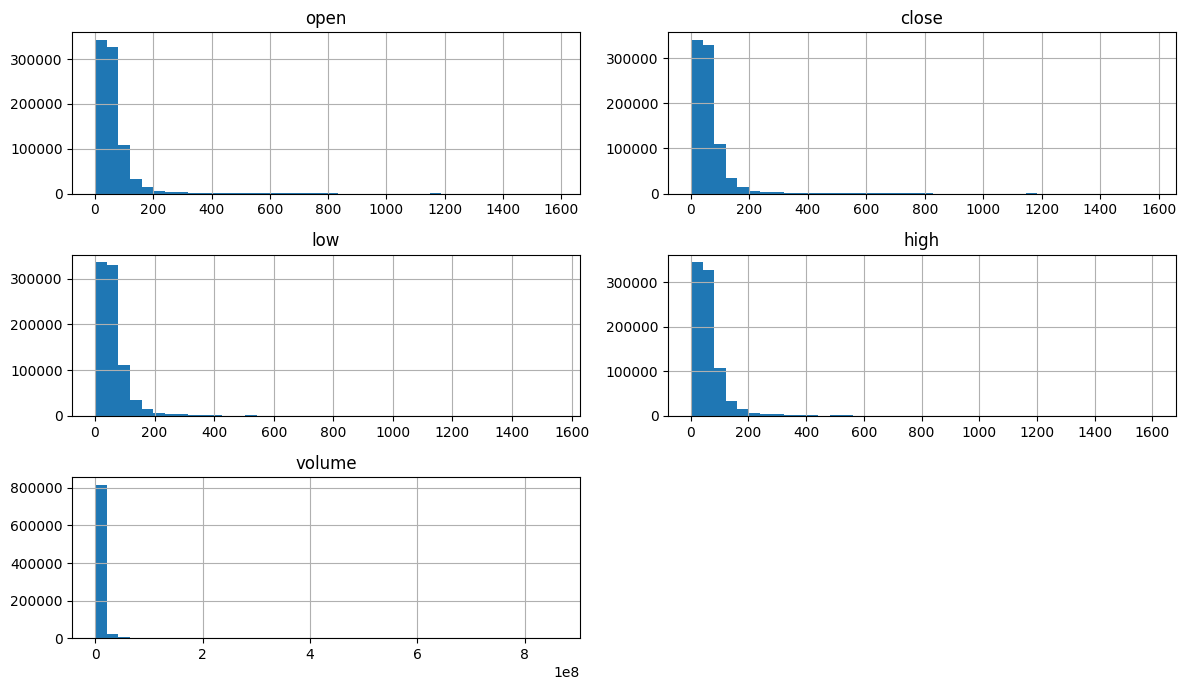

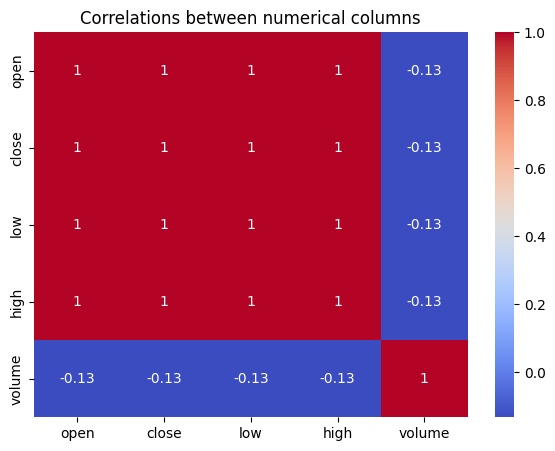

In [10]:
import seaborn as sns

columns = ["open", "close", "low", "high", "volume"]

df[columns].hist(bins=40, figsize=(12, 7))
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df[columns].corr(), annot=True, cmap="coolwarm")
plt.title("Correlations between numerical columns")
plt.show()

### Observations
There are 851,264 rows and 501 stock symbols, covering 2010 to 2016. The checks found no missing values or duplicate rows.

Most prices are concentrated in the lower ranges, with a few much higher values. Open, close, low and high are strongly correlated: they describe prices of the same stock on the same day. This does not mean they will necessarily predict the next day's price well. The Apple chart only shows historical prices.

In [11]:
data = df.sort_values(["symbol", "date"]).copy()

data["next_close"] = data.groupby("symbol")["close"].shift(-1)

data["target_date"] = data.groupby("symbol")["date"].shift(-1)

data = data.dropna(subset=["next_close", "target_date"])

display(
    data[["symbol", "date", "close", "target_date", "next_close"]].head()
)

,symbol,date,close,target_date,next_close
251,A,2010-01-04,22.389128,2010-01-05,22.145923
718,A,2010-01-05,22.145923,2010-01-06,22.067240
1186,A,2010-01-06,22.067240,2010-01-07,22.038626
1654,A,2010-01-07,22.038626,2010-01-08,22.031474
2122,A,2010-01-08,22.031474,2010-01-11,22.045780


## 2. Preparing the inputs and target
`next_close` is the next trading day's closing price for the same company. The last row of each company is removed because its next price is unknown.

The split follows time: training before 2015, validation in 2015 and testing in 2016. Pairs crossing these boundaries are excluded. There are 599,692 training rows, 124,458 validation rows and 125,624 test rows.

The scalers are fitted on training data only, then applied to validation and test data.

In [12]:
features = ["open", "close", "low", "high", "volume"]

train = data[data["target_date"] < "2015-01-01"].copy()

val = data[
    (data["date"] >= "2015-01-01") &
    (data["target_date"] < "2016-01-01")
].copy()

test = data[data["date"] >= "2016-01-01"].copy()

print("Training rows:", len(train))
print("Validation rows:", len(val))
print("Test rows:", len(test))

Training rows: 599692
Validation rows: 124458
Test rows: 125624


In [13]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(train[features]).astype("float32")
X_val = x_scaler.transform(val[features]).astype("float32")
X_test = x_scaler.transform(test[features]).astype("float32")

y_train = y_scaler.fit_transform(train[["next_close"]]).astype("float32")
y_val = y_scaler.transform(val[["next_close"]]).astype("float32")
y_test = y_scaler.transform(test[["next_close"]]).astype("float32")

print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)

Training inputs: (599692, 5)
Training targets: (599692, 1)


## 3. First neural network
The first MLP has 5 inputs, two hidden layers with 64 and 32 neurons, and one output. It uses ReLU, Adam and MSE loss, and is trained for 10 epochs.

In [14]:
import torch
from torch import nn

torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(5, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

print(model)

Sequential(
  (0): Linear(in_features=5, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


In [15]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)
train_loader = DataLoader(train_ds, batch_size=1024, shuffle=True)

X_val_t = torch.from_numpy(X_val)
y_val_t = torch.from_numpy(y_val)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_losses = []
val_losses = []

for epoch in range(10):
    model.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        predictions = model(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        for xb, yb in train_loader:
            total_loss += criterion(model(xb), yb).item() * len(xb)

        train_loss = total_loss / len(train_ds)
        val_loss = criterion(model(X_val_t), y_val_t).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/10 | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

Epoch 1/10 | Train MSE: 0.000776 | Validation MSE: 0.001880
Epoch 2/10 | Train MSE: 0.000645 | Validation MSE: 0.001509
Epoch 3/10 | Train MSE: 0.000642 | Validation MSE: 0.001487
Epoch 4/10 | Train MSE: 0.000633 | Validation MSE: 0.001470
Epoch 5/10 | Train MSE: 0.000734 | Validation MSE: 0.001567
Epoch 6/10 | Train MSE: 0.000658 | Validation MSE: 0.001551
Epoch 7/10 | Train MSE: 0.000741 | Validation MSE: 0.001788
Epoch 8/10 | Train MSE: 0.000597 | Validation MSE: 0.001353
Epoch 9/10 | Train MSE: 0.000562 | Validation MSE: 0.001289
Epoch 10/10 | Train MSE: 0.000745 | Validation MSE: 0.001751


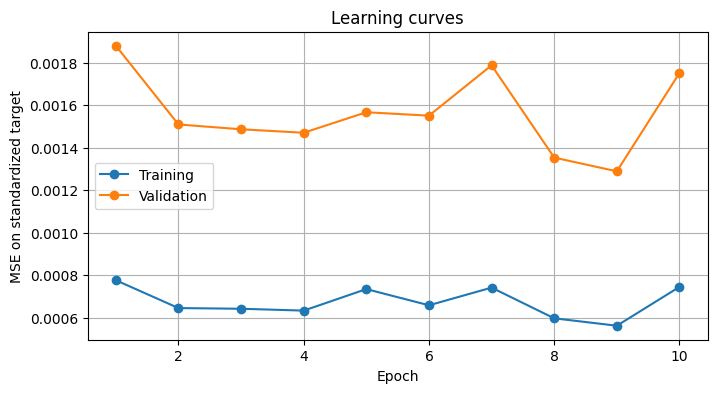

In [16]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_losses, marker="o", label="Training")
plt.plot(epochs, val_losses, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE on standardized target")
plt.title("Learning curves")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

model.eval()
with torch.no_grad():
    pred_scaled = model(X_val_t).numpy()

pred = y_scaler.inverse_transform(pred_scaled).ravel()
actual = val["next_close"].to_numpy()
baseline = val["close"].to_numpy()

results = pd.DataFrame({
    "Model": ["Neural network (epoch 10)", "Today = next day"],
    "MAE (USD)": [
        mean_absolute_error(actual, pred),
        mean_absolute_error(actual, baseline)
    ],
    "RMSE (USD)": [
        np.sqrt(mean_squared_error(actual, pred)),
        np.sqrt(mean_squared_error(actual, baseline))
    ]
})

display(results)

,Model,MAE (USD),RMSE (USD)
0,Neural network (epoch 10),1.215386,2.544084
1,Today = next day,0.962560,2.104463


### First result
The validation MAE is $1.22, compared with $0.96 when simply using today's closing price as the next prediction. So the first network does worse than this simple baseline.

## 4. GridSearchCV
The search tests 16 combinations: two learning rates, two hidden-layer sizes, two epoch counts and two optimizers. It uses the existing chronological validation split, rather than several cross-validation folds. The test set is kept aside.

In [18]:
%pip -q install skorch

In [19]:
import numpy as np
import torch
from torch import nn

from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit

# A network whose size can be changed by GridSearchCV
class RegressionMLP(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(5, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, x):
        return self.layers(x)


# Combine training and validation, while keeping their roles separate
X_search = np.concatenate([X_train, X_val])
y_search = np.concatenate([y_train, y_val])

split = PredefinedSplit(
    np.concatenate([
        np.full(len(X_train), -1),  # Used for training
        np.zeros(len(X_val))        # Used for validation
    ])
)

net = NeuralNetRegressor(
    RegressionMLP,
    criterion=nn.MSELoss,
    batch_size=1024,
    train_split=None,
    iterator_train__shuffle=True,
    verbose=0,
    device="cuda" if torch.cuda.is_available() else "cpu"
)

# Try 16 combinations
parameters = {
    "lr": [0.001, 0.0001],
    "module__hidden": [32, 64],
    "max_epochs": [10, 20],
    "optimizer": [torch.optim.Adam, torch.optim.RMSprop]
}

torch.manual_seed(42)

search = GridSearchCV(
    net,
    parameters,
    scoring="neg_mean_squared_error",
    cv=split,
    refit=False,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

search.fit(X_search, y_search)

print("Best settings:", search.best_params_)
print("Best validation MSE:", -search.best_score_)

Fitting 1 folds for each of 16 candidates, totalling 16 fits
[CV] END lr=0.001, max_epochs=10, module__hidden=32, optimizer=<class 'torch.optim.adam.Adam'>; total time= 1.3min
[CV] END lr=0.001, max_epochs=10, module__hidden=32, optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time= 1.1min
[CV] END lr=0.001, max_epochs=10, module__hidden=64, optimizer=<class 'torch.optim.adam.Adam'>; total time= 1.2min
[CV] END lr=0.001, max_epochs=10, module__hidden=64, optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time= 1.1min
[CV] END lr=0.001, max_epochs=20, module__hidden=32, optimizer=<class 'torch.optim.adam.Adam'>; total time= 2.2min
[CV] END lr=0.001, max_epochs=20, module__hidden=32, optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time= 2.2min
[CV] END lr=0.001, max_epochs=20, module__hidden=64, optimizer=<class 'torch.optim.adam.Adam'>; total time= 2.4min
[CV] END lr=0.001, max_epochs=20, module__hidden=64, optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time= 2.

### Best settings
The best combination tested is Adam, learning rate 0.001, 20 epochs and hidden layers of 32 and 16 neurons. Its validation MSE is 0.0012429205 on standardized prices.

The next cell trains this configuration again. Its result may differ slightly because the random initialization differs from the winning search run.

In [20]:
from skorch.helper import predefined_split
from skorch.dataset import Dataset

torch.manual_seed(42)

best_net = NeuralNetRegressor(
    RegressionMLP,
    criterion=nn.MSELoss,
    batch_size=1024,
    iterator_train__shuffle=True,
    train_split=predefined_split(Dataset(X_val, y_val)),
    device="cuda" if torch.cuda.is_available() else "cpu",
    verbose=1,
    **search.best_params_
)

best_net.fit(X_train, y_train)

  epoch    train_loss    valid_loss      dur
-------  ------------  ------------  -------
      1        0.0449        0.0016  13.1052
      2        0.0007        0.0016  8.4593
      3        0.0007        0.0015  7.9341
      4        0.0007        0.0017  8.3312
      5        0.0007        0.0018  8.7167
      6        0.0007        0.0017  7.3004
      7        0.0007        0.0016  8.5235
      8        0.0007        0.0021  8.4938
      9        0.0007        0.0015  7.3126
     10        0.0007        0.0014  8.4523
     11        0.0007        0.0014  7.4912
     12        0.0007        0.0016  8.4274
     13        0.0006        0.0015  8.4528
     14        0.0006        0.0017  7.1987
     15        0.0006        0.0015  8.4270
     16        0.0006        0.0015  8.2903
     17        0.0006        0.0013  7.6869
     18        0.0006        0.0013  8.5658
     19        0.0006        0.0014  7.1739
     20        0.0006        0.0016  8.4242


<class 'skorch.regressor.NeuralNetRegressor'>[initialized](
  module_=RegressionMLP(
    (layers): Sequential(
      (0): Linear(in_features=5, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=16, bias=True)
      (3): ReLU()
      (4): Linear(in_features=16, out_features=1, bias=True)
    )
  ),
)

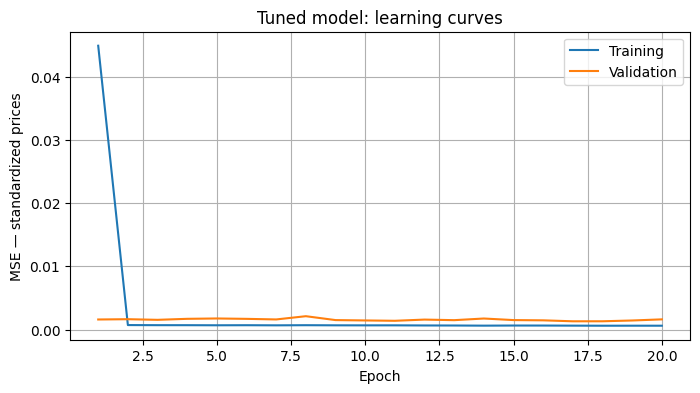

,Method,MAE (USD),RMSE (USD)
0,Tuned network — epoch 20,1.072572,2.443672
1,Next price = today's price,0.962560,2.104463


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

history = pd.DataFrame(best_net.history)

plt.figure(figsize=(8, 4))
plt.plot(history["epoch"], history["train_loss"], label="Training")
plt.plot(history["epoch"], history["valid_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE — standardized prices")
plt.title("Tuned model: learning curves")
plt.legend()
plt.grid(True)
plt.show()

# Convert predictions back to dollars
pred_val = y_scaler.inverse_transform(
    best_net.predict(X_val)
).ravel()

actual = val["next_close"].to_numpy()
baseline = val["close"].to_numpy()

comparison = pd.DataFrame({
    "Method": ["Tuned network — epoch 20", "Next price = today's price"],
    "MAE (USD)": [
        mean_absolute_error(actual, pred_val),
        mean_absolute_error(actual, baseline)
    ],
    "RMSE (USD)": [
        np.sqrt(mean_squared_error(actual, pred_val)),
        np.sqrt(mean_squared_error(actual, baseline))
    ]
})

display(comparison)

## 5. Trying regularization
Dropout 0.1 and weight decay 0.0001 are tested separately on the tuned network.

| Model | Validation MAE ($) | Validation RMSE ($) |
|---|---:|---:|
| First network | 1.215386 | 2.544084 |
| Tuned network | 1.072572 | 2.443672 |
| Weight decay | 1.110217 | 2.512901 |
| Dropout | 1.791637 | 4.879515 |
| Today's price baseline | 0.962560 | 2.104463 |

Tuning helped compared with the first network. Neither regularization setting improved the tuned result. Dropout gave the largest errors. Its training loss includes active dropout, while evaluation disables it, so the two losses need care when comparing.

In [23]:
class RegularizedMLP(nn.Module):
    def __init__(self, hidden=32, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(5, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1)
        )

    def forward(self, x):
        return self.layers(x)


# Keep the tuned network so we can compare all three
reg_models = {"Tuned network": best_net}

experiments = [
    ("Weight decay", 0.0, 0.0001),
    ("Dropout", 0.1, 0.0)
]

for name, dropout, weight_decay in experiments:
    torch.manual_seed(42)

    candidate = NeuralNetRegressor(
        RegularizedMLP,
        module__hidden=32,
        module__dropout=dropout,
        criterion=nn.MSELoss,
        optimizer=torch.optim.Adam,
        optimizer__weight_decay=weight_decay,
        lr=0.001,
        max_epochs=20,
        batch_size=1024,
        iterator_train__shuffle=True,
        train_split=predefined_split(Dataset(X_val, y_val)),
        device=best_net.device,
        verbose=1
    )

    print(f"\nTraining: {name}")
    candidate.fit(X_train, y_train)
    reg_models[name] = candidate


# Compare validation predictions in dollars
rows = []

for name, candidate in reg_models.items():
    predictions = y_scaler.inverse_transform(
        candidate.predict(X_val)
    ).ravel()

    rows.append({
        "Method": name,
        "MAE (USD)": mean_absolute_error(actual, predictions),
        "RMSE (USD)": np.sqrt(
            mean_squared_error(actual, predictions)
        )
    })

rows.append({
    "Method": "Next price = today's price",
    "MAE (USD)": mean_absolute_error(actual, baseline),
    "RMSE (USD)": np.sqrt(mean_squared_error(actual, baseline))
})

reg_results = pd.DataFrame(rows)
display(reg_results.sort_values("RMSE (USD)"))


Training: Weight decay
  epoch    train_loss    valid_loss     dur
-------  ------------  ------------  ------
      1        0.0449        0.0016  8.9901
      2        0.0007        0.0015  8.8696
      3        0.0007        0.0015  7.6040
      4        0.0007        0.0016  8.9676
      5        0.0007        0.0015  9.3047
      6        0.0007        0.0014  7.7820
      7        0.0007        0.0015  9.5477
      8        0.0007        0.0021  8.9275
      9        0.0007        0.0015  7.5528
     10        0.0007        0.0014  10.0686
     11        0.0007        0.0014  9.1794
     12        0.0006        0.0016  8.2513
     13        0.0006        0.0014  9.3463
     14        0.0006        0.0016  9.3255
     15        0.0006        0.0013  11.4732
     16        0.0006        0.0014  12.9219
     17        0.0006        0.0013  8.0553
     18        0.0006        0.0013  9.1423
     19        0.0006        0.0014  9.1604
     20        0.0006        0.0017  8.6732

Trai

,Method,MAE (USD),RMSE (USD)
3,Next price = today's price,0.962560,2.104463
0,Tuned network,1.072572,2.443672
1,Weight decay,1.110217,2.512901
2,Dropout,1.791637,4.879515


## 6. Testing the selected model
The tuned network is selected using validation RMSE. The following table reports its training and test results.

In [24]:
from sklearn.metrics import r2_score

# Select the neural network using validation results only
selected_name = (
    reg_results[
        reg_results["Method"].isin(reg_models)
    ]
    .sort_values("RMSE (USD)")
    .iloc[0]["Method"]
)

selected_net = reg_models[selected_name]
print("Selected neural network:", selected_name)

# Evaluate training and test data in dollars
final_rows = []

for split_name, X, frame in [
    ("Training", X_train, train),
    ("Test", X_test, test)
]:
    actual_prices = frame["next_close"].to_numpy()

    network_predictions = y_scaler.inverse_transform(
        selected_net.predict(X)
    ).ravel()

    for method, predictions in [
        (selected_name, network_predictions),
        ("Next price = today's price", frame["close"].to_numpy())
    ]:
        final_rows.append({
            "Dataset": split_name,
            "Method": method,
            "MAE (USD)": mean_absolute_error(actual_prices, predictions),
            "RMSE (USD)": np.sqrt(
                mean_squared_error(actual_prices, predictions)
            ),
            "R²": r2_score(actual_prices, predictions)
        })

final_results = pd.DataFrame(final_rows)
display(final_results)

Selected neural network: Tuned network


,Dataset,Method,MAE (USD),RMSE (USD),R²
0,Training,Tuned network,0.699534,1.572187,0.999331
1,Training,Next price = today's price,0.647236,1.388302,0.999478
2,Test,Tuned network,1.076454,2.512573,0.999409
3,Test,Next price = today's price,0.948386,2.142949,0.999570


## 7. Learning curves
The assignment asks for accuracy versus epochs. Since this task predicts a continuous price, R² is plotted instead. **R² is a regression score, not an accuracy percentage.** A teacher-specific accuracy definition would need to be clarified.

A separate training run records training/test MSE and R² after each epoch. Its settings and 20-epoch duration are fixed in advance; the test curves are not used to change them. Its results can differ from the previous fit.

  epoch    train_loss     dur
-------  ------------  ------
      1        0.0449  8.2825
      2        0.0007  7.8170
      3        0.0007  6.9457
      4        0.0007  6.7470
      5        0.0007  7.4777
      6        0.0007  6.9852
      7        0.0007  6.5708
      8        0.0007  7.4461
      9        0.0007  7.2870
     10        0.0007  7.5642
     11        0.0007  7.4971
     12        0.0007  7.7299
     13        0.0006  6.3257
     14        0.0007  7.5805
     15        0.0007  7.5538
     16        0.0006  6.3953
     17        0.0006  6.9897
     18        0.0006  7.6399
     19        0.0006  6.3337
     20        0.0006  6.5530


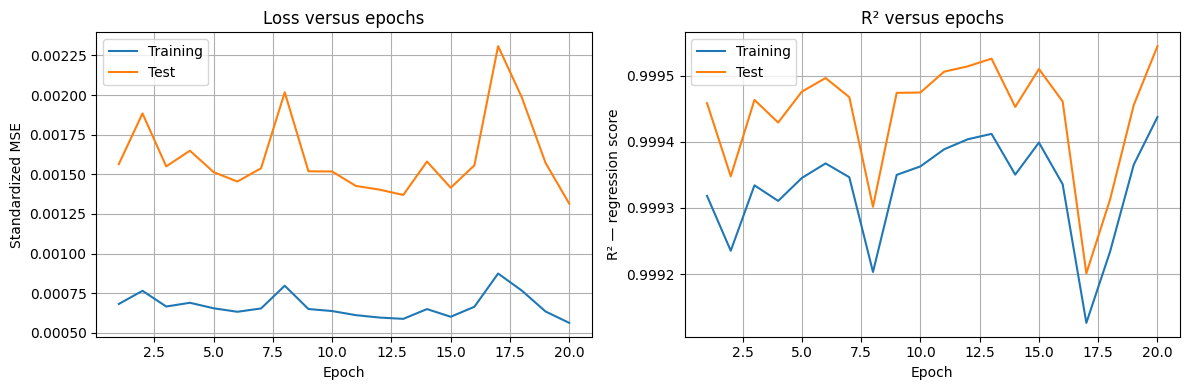

In [25]:
from sklearn.base import clone
from skorch.callbacks import Callback
from sklearn.metrics import mean_squared_error, r2_score

class RecordCurves(Callback):
    def on_train_begin(self, net, **kwargs):
        self.rows = []

    def on_epoch_end(self, net, **kwargs):
        row = {"Epoch": len(net.history)}

        for name, X, y in [
            ("Training", X_train, y_train),
            ("Test", X_test, y_test)
        ]:
            predictions = net.predict(X)
            row[f"{name} MSE"] = mean_squared_error(y, predictions)
            row[f"{name} R²"] = r2_score(y, predictions)

        self.rows.append(row)

recorder = RecordCurves()

torch.manual_seed(42)
report_net = clone(best_net).set_params(
    train_split=None,
    callbacks=[("curves", recorder)],
    verbose=1
)
report_net.fit(X_train, y_train)

curves = pd.DataFrame(
    dict(report_net.callbacks_)["curves"].rows
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name in ["Training", "Test"]:
    axes[0].plot(curves["Epoch"], curves[f"{name} MSE"], label=name)
    axes[1].plot(curves["Epoch"], curves[f"{name} R²"], label=name)

axes[0].set(title="Loss versus epochs", ylabel="Standardized MSE")
axes[1].set(title="R² versus epochs", ylabel="R² — regression score")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Results and conclusion
The loss curves fluctuate, and test MSE stays above training MSE. They do not show a steady late increase in test error. Test R² can be higher despite larger errors because price variation differs between the training and test sets.

In the earlier final evaluation, the tuned network has a test MAE of **$1.08** and RMSE of **$2.51**. The simple baseline gives **$0.95** and **$2.14**. The network therefore does not beat the baseline. Its high R² of 0.999409 is not enough to claim good forecasting performance, especially with widely different price levels across companies.

### What I learned
This part helped me understand how to create a target, split time-based data and train an MLP. The main lesson is to compare the model with a simple baseline. More layers, tuning or regularization do not automatically give better predictions.